## Docker for Prototype Development: Pose Fitting Virtual Makeup Demo

#### Author           : Dr. Sujoy Kumar Biswas, Ph.D., M.Tech.
####                   Head of Research & Innovation
####                   IDEAS - Technology Innovation Hub, Indian Statistical Institute (ISI), Kolkata
####                   Founder, AIMP LABS (www.aimplabs.org)

#### Target Audience  : IDEAS-TIH Research & Engineering Interns (Autumn 2026)
--------------------------------------------------------------------------------

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import mediapipe as mp
import os

# Suppress verbose backend logs
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

mp_face_mesh = mp.solutions.face_mesh
face_mesh = mp_face_mesh.FaceMesh(
    static_image_mode=True,
    max_num_faces=1,
    refine_landmarks=False,
    min_detection_confidence=0.5
)

OUTER_LIPS = [61, 185, 40, 39, 37, 0, 267, 269, 270, 409, 291, 375, 321, 405, 314, 17, 84, 181, 91, 146]
INNER_LIPS = [78, 191, 80, 81, 82, 13, 312, 311, 310, 415, 308, 324, 318, 402, 317, 14, 87, 178, 88, 95]

INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1791780043.396123   64705 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


W0000 00:00:1791780043.401068   64704 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


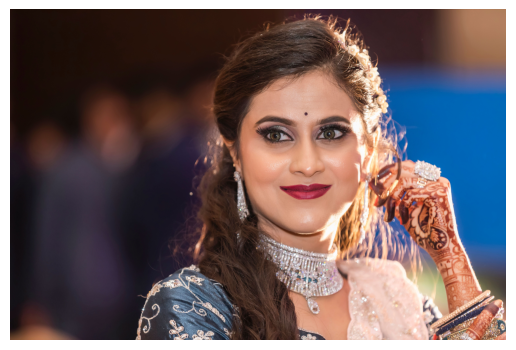

In [4]:
image_bgr = cv2.imread("pexels-shootsaga-31381691.jpg")
# Convert BGR to RGB
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
plt.imshow(image_rgb)
plt.axis('off')
plt.show()

In [51]:
# Explicitly ordered paths to create two independent closed loops
# Upper Lip: Left Corner -> Outer Top -> Right Corner -> Inner Top -> Left Corner
UPPER_LIP_OUTER = [61, 185, 40, 39, 37, 0, 267, 269, 270, 409, 291]
UPPER_LIP_INNER = [308, 415, 310, 311, 312, 13, 82, 81, 80, 191, 78]

# Lower Lip: Right Corner -> Outer Bottom -> Left Corner -> Inner Bottom -> Right Corner
LOWER_LIP_OUTER = [291, 375, 321, 405, 314, 17, 84, 181, 91, 146, 61]
LOWER_LIP_INNER = [78, 95, 88, 178, 87, 14, 317, 402, 318, 324, 308]

def apply_lipstick_still_v4(image_rgb: np.ndarray, landmarks, rgb_color: list, intensity: float = 0.65) -> np.ndarray:
    h, w, _ = image_rgb.shape

    # 1. Build the Upper Lip Polygon
    upper_pts = np.array([
        [int(landmarks.landmark[idx].x * w), int(landmarks.landmark[idx].y * h)] 
        for idx in UPPER_LIP_OUTER + UPPER_LIP_INNER
    ], dtype=np.int32)
    
    # 2. Build the Lower Lip Polygon
    lower_pts = np.array([
        [int(landmarks.landmark[idx].x * w), int(landmarks.landmark[idx].y * h)] 
        for idx in LOWER_LIP_OUTER + LOWER_LIP_INNER
    ], dtype=np.int32)

    # 3. Draw both polygons directly onto the mask
    mask = np.zeros((h, w), dtype=np.uint8)
    cv2.fillPoly(mask, [upper_pts], 255)
    cv2.fillPoly(mask, [lower_pts], 255)

    # 4. Strict Anatomical Confinement
    # Dilation is completely removed to prevent the bottom shelf overfill.
    
    # 5. Micro-Feathering
    lip_width = np.max(upper_pts[:, 0]) - np.min(upper_pts[:, 0])
    blur_size = max(3, int(lip_width * 0.03)) | 1  
    mask_feathered = cv2.GaussianBlur(mask, (blur_size, blur_size), sigmaX=0)

    # 6. Flat RGB Blend
    color_canvas = np.full_like(image_rgb, rgb_color, dtype=np.uint8)
    tinted_frame = cv2.addWeighted(image_rgb, 1.0 - intensity, color_canvas, intensity, 0)

    alpha = (mask_feathered.astype(np.float32) / 255.0)[:, :, np.newaxis]
    return (alpha * tinted_frame + (1.0 - alpha) * image_rgb).astype(np.uint8)

/home/py311/lib/python3.11/site-packages/google/protobuf/symbol_database.py:55: UserWarning: SymbolDatabase.GetPrototype() is deprecated. Please use message_factory.GetMessageClass() instead. SymbolDatabase.GetPrototype() will be removed soon.
  warnings.warn('SymbolDatabase.GetPrototype() is deprecated. Please '


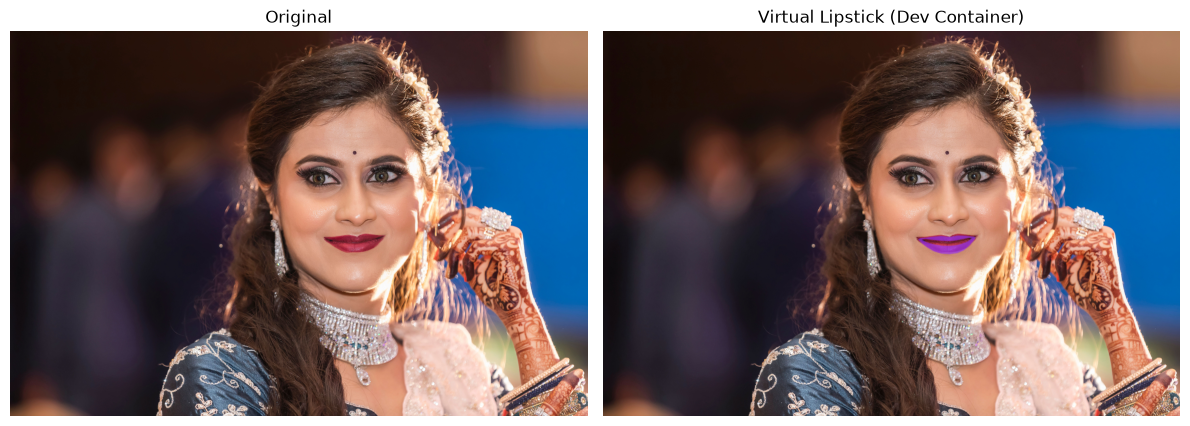

In [52]:
# Load image using headless OpenCV
image_bgr = cv2.imread("pexels-shootsaga-31381691.jpg")
if image_bgr is None:
    raise ValueError("Image not found. Ensure 'pexels-fahadputhawala-33965312.jpg' is in the /home/codebase directory.")

# Convert BGR to RGB for MediaPipe and Matplotlib
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
results = face_mesh.process(image_rgb)

PALETTE = {
    # Existing warm colors (will blend invisibly into her dark red lips)
    "Ruby Red":     [50, 20, 200],   # BGR
    "Crimson":      [60, 40, 160],
    "Plum":         [110, 40, 130],
    "Coral":        [90, 100, 230],
    "Natural Tint": [70, 70, 180],
    
    # New high-contrast colors (will show massive visual changes)
    "Electric Blue":[250, 200, 0],   # BGR -> RGB: [0, 200, 250]
    "Neon Violet":  [255, 50, 150],  # BGR -> RGB: [150, 50, 255]
    "Gold":         [0, 215, 255]    # BGR -> RGB: [255, 215, 0]
}

if results.multi_face_landmarks:
    active_bgr = PALETTE["Neon Violet"]
    active_rgb = active_bgr[::-1]
    output_image = apply_lipstick_still_v4(image_rgb, results.multi_face_landmarks[0], active_rgb)


    # Render directly in the VS Code Notebook UI
    fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    axes[0].imshow(image_rgb)
    axes[0].set_title("Original")
    axes[0].axis('off')
    
    axes[1].imshow(output_image)
    axes[1].set_title("Virtual Lipstick (Dev Container)")
    axes[1].axis('off')
    
    plt.tight_layout()
    plt.show()
else:
    print("No face detected in the image.")

In [53]:
# Convert the RGB output back to BGR for OpenCV saving
output_image_bgr = cv2.cvtColor(output_image, cv2.COLOR_RGB2BGR)

# Save the image inside the Docker container
output_filename = "output_face_v4.jpg"
cv2.imwrite(output_filename, output_image_bgr)

print(f"Successfully saved {output_filename} inside the container!")

Successfully saved output_face_v4.jpg inside the container!


In [22]:
def apply_lipstick_photorealistic(image_rgb: np.ndarray, landmarks, rgb_color: list, intensity: float = 0.70) -> np.ndarray:
    h, w, _ = image_rgb.shape

    # 1. Coordinate Extraction
    outer_pts = np.array([[int(landmarks.landmark[idx].x * w), int(landmarks.landmark[idx].y * h)] for idx in OUTER_LIPS], dtype=np.int32)
    inner_pts = np.array([[int(landmarks.landmark[idx].x * w), int(landmarks.landmark[idx].y * h)] for idx in INNER_LIPS], dtype=np.int32)

    # Calculate bounding geometry
    lip_width = np.max(outer_pts[:, 0]) - np.min(outer_pts[:, 0])
    
    # 2. Build the base outer mask
    mask = np.zeros((h, w), dtype=np.uint8)
    cv2.fillPoly(mask, [outer_pts], 255)

    # 3. Scale-Invariant Teeth Cutout
    # Landmark 13 is top inner lip, 14 is bottom inner lip
    top_y = int(landmarks.landmark[13].y * h)
    bottom_y = int(landmarks.landmark[14].y * h)
    mouth_gap = bottom_y - top_y

    # Only punch the inner hole if the vertical gap is greater than 4% of the total lip width.
    # This prevents high-res closed mouths from triggering the teeth cutout.
    if mouth_gap > (lip_width * 0.04):
        cv2.fillPoly(mask, [inner_pts], 0)

    # 4. Morphological Dilation
    dilate_size = max(3, int(lip_width * 0.05))
    mask = cv2.dilate(mask, np.ones((dilate_size, dilate_size), np.uint8), iterations=1)

    blur_size = max(3, int(lip_width * 0.08)) | 1
    mask_feathered = cv2.GaussianBlur(mask, (blur_size, blur_size), sigmaX=0)

    # 3. LAB Color Space Blending (The Photorealistic Secret)
    # Convert underlying image and the target color canvas to LAB
    img_lab = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2LAB)
    
    color_canvas = np.full_like(image_rgb, rgb_color, dtype=np.uint8)
    color_lab = cv2.cvtColor(color_canvas, cv2.COLOR_RGB2LAB)

    # Create a tinted LAB image
    tinted_lab = img_lab.copy()
    
    # CRITICAL: Do NOT touch tinted_lab[:, :, 0] (The 'L' Lightness channel). 
    # This preserves 100% of the original gloss, shadows, and lip texture.
    
    # Blend only the 'a' (Green-Red) and 'b' (Blue-Yellow) color channels
    tinted_lab[:, :, 1] = cv2.addWeighted(img_lab[:, :, 1], 1.0 - intensity, color_lab[:, :, 1], intensity, 0)
    tinted_lab[:, :, 2] = cv2.addWeighted(img_lab[:, :, 2], 1.0 - intensity, color_lab[:, :, 2], intensity, 0)

    # Convert back to RGB
    tinted_rgb = cv2.cvtColor(tinted_lab, cv2.COLOR_LAB2RGB)

    # 4. Final Spatial Alpha Composite
    alpha = (mask_feathered.astype(np.float32) / 255.0)[:, :, np.newaxis]
    return (alpha * tinted_rgb + (1.0 - alpha) * image_rgb).astype(np.uint8)

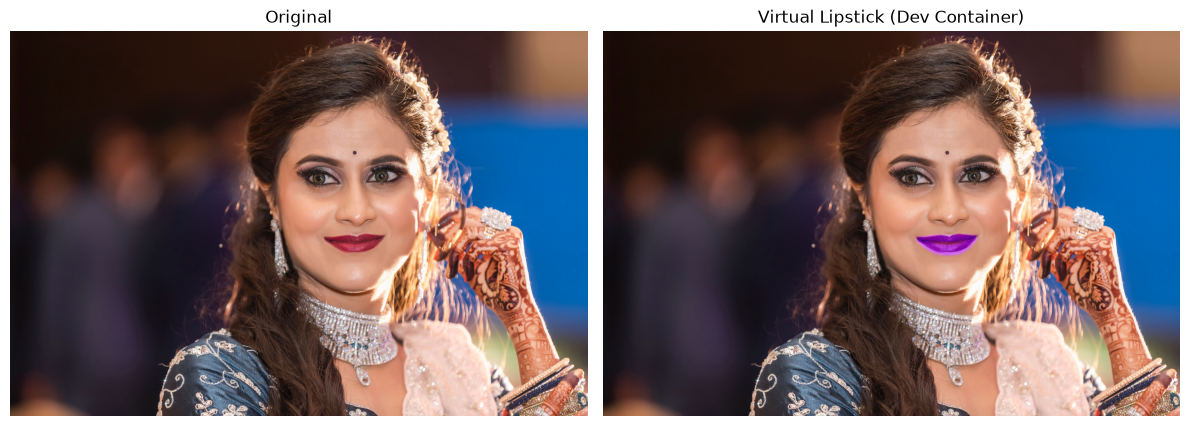

In [37]:
# Load image using headless OpenCV
image_bgr = cv2.imread("pexels-shootsaga-31381691.jpg")
if image_bgr is None:
    raise ValueError("Image not found. Ensure 'pexels-fahadputhawala-33965312.jpg' is in the /home/codebase directory.")

# Convert BGR to RGB for MediaPipe and Matplotlib
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
results = face_mesh.process(image_rgb)

PALETTE = {
    # Existing warm colors (will blend invisibly into her dark red lips)
    "Ruby Red":     [50, 20, 200],   # BGR
    "Crimson":      [60, 40, 160],
    "Plum":         [110, 40, 130],
    "Coral":        [90, 100, 230],
    "Natural Tint": [70, 70, 180],
    
    # New high-contrast colors (will show massive visual changes)
    "Electric Blue":[250, 200, 0],   # BGR -> RGB: [0, 200, 250]
    "Neon Violet":  [255, 50, 150],  # BGR -> RGB: [150, 50, 255]
    "Gold":         [0, 215, 255]    # BGR -> RGB: [255, 215, 0]
}

if results.multi_face_landmarks:
    active_bgr = PALETTE["Neon Violet"]
    active_rgb = active_bgr[::-1]
    output_image = apply_lipstick_photorealistic(image_rgb, results.multi_face_landmarks[0], active_rgb)

    # Render directly in the VS Code Notebook UI
    fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    axes[0].imshow(image_rgb)
    axes[0].set_title("Original")
    axes[0].axis('off')
    
    axes[1].imshow(output_image)
    axes[1].set_title("Virtual Lipstick (Dev Container)")
    axes[1].axis('off')
    
    plt.tight_layout()
    plt.show()
else:
    print("No face detected in the image.")

In [38]:
# Convert the RGB output back to BGR for OpenCV saving
output_image_bgr = cv2.cvtColor(output_image, cv2.COLOR_RGB2BGR)

# Save the image inside the Docker container
output_filename = "output_face_modified.jpg"
cv2.imwrite(output_filename, output_image_bgr)

print(f"Successfully saved {output_filename} inside the container!")

Successfully saved output_face_modified.jpg inside the container!
